# Predikčná analýza: vysoký dopad incidentu a rozdelenie 70:30

Notebook porovnáva logistickú regresiu a LightGBM pri zjednodušenej úlohe. Nadväzuje na `priprava_dat.ipynb`, ktorý musí byť spustený ako prvý.

Oproti notebooku `predikcia.ipynb` sa menia dve veci:

| | `predikcia.ipynb` | Tento notebook |
| --- | --- | --- |
| **Triedy** | `nízky`, `stredný`, `vysoký` | `nízky alebo stredný`, `vysoký` |
| **Rozdelenie dát** | podľa zdroja incidentu, hromadné zdroje iba v tréningu | náhodné 70:30, seed 67, zachovaný pomer tried |

Úloha teda odpovedá na otázku, či incident pravdepodobne povedie k úniku aspoň 100 000 záznamov. Výstupom sú tabuľky metrík, `figures/5_f1_2_triedy.png` a `figures/6_matice_zamen_2_triedy.png`.

**Prevencia úniku informácií.** Vstupy sú rovnaké ako v `predikcia.ipynb`: iba informácie známe hneď po odhalení incidentu, bez popisu a bez počtu záznamov.

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from vcdb_model import make_features

DATA_PATH = Path("data/processed/vcdb_clean.csv")
FIGURES_DIR = Path("figures")
LABELS = ["nízky alebo stredný", "vysoký"]
SEED = 67

clean = pd.read_csv(DATA_PATH, low_memory=False)

## 1. Načítanie dát a zlúčenie tried

In [2]:
data = clean[clean["dopad"].notna()].reset_index(drop=True)
data["target"] = (data["dopad"] == "vysoký").astype(int)
counts = data["target"].map(dict(enumerate(LABELS))).value_counts().reindex(LABELS)
display(pd.DataFrame({"počet": counts, "podiel %": (counts / len(data) * 100).round(1)}))

,počet,podiel %
target,,
nízky alebo stredný,4214,82.7
vysoký,883,17.3


## 2. Rozdelenie dát

Dáta sú rozdelené náhodne v pomere **70 % tréning a 30 % test** so seedom 67. Parameter `stratify` zachováva pomer tried v oboch častiach.

Parametre sa vyberajú na validačnej časti, ktorá tvorí 20 % z tréningovej množiny. Testovacia množina sa do výberu nezapája. Po výbere parametrov sa model naučí na celých 70 %.

**Pozor:** náhodné rozdelenie nerešpektuje zdroj incidentu. Takmer rovnaké incidenty z jedného zoznamu sa preto môžu ocitnúť v tréningu aj v teste. Časť 5 to kontroluje.

In [3]:
train, test = train_test_split(data, test_size=0.30, random_state=SEED, stratify=data["target"])
fit, validation = train_test_split(train, test_size=0.20, random_state=SEED, stratify=train["target"])
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
y_train, y_test = train["target"].to_numpy(), test["target"].to_numpy()

display(pd.DataFrame({
    "počet": [len(fit), len(validation), len(train), len(test)],
    "vysoký %": [part["target"].mean() * 100 for part in [fit, validation, train, test]],
}, index=["učenie", "validácia", "tréning spolu", "test"]).round(1))

,počet,vysoký %
učenie,2853,17.3
validácia,714,17.4
tréning spolu,3567,17.3
test,1530,17.3


## 3. Príprava znakov

Znaky sú rovnaké ako v `predikcia.ipynb` a pripravuje ich modul `vcdb_model.py`. Slovník hodnôt sa učí iba z tréningových dát.

## 4. Výber parametrov

Parametre sa vyberajú podľa macro F1 na validačnej časti.

In [4]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=[0, 1], zero_division=0)


def make_logreg(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=SEED)


def make_lightgbm(num_leaves, n_estimators):
    return lgb.LGBMClassifier(
        objective="binary",
        class_weight="balanced",
        n_estimators=n_estimators,
        learning_rate=0.05,
        num_leaves=num_leaves,
        min_child_samples=20,
        colsample_bytree=0.5,
        subsample=0.8,
        subsample_freq=1,
        reg_lambda=1.0,
        random_state=SEED,
        deterministic=True,
        force_row_wise=True,
        n_jobs=4,
        verbosity=-1,
    )


candidates = {f"LR C={C}": make_logreg(C) for C in [0.1, 0.3, 1, 3]}
candidates.update({
    f"LightGBM listy={leaves} stromy={trees}": make_lightgbm(leaves, trees)
    for leaves in [15, 31] for trees in [100, 250, 500]
})

rows = []
for name, model in candidates.items():
    pipeline = Pipeline([("features", make_features()), ("model", clone(model))]).fit(fit, fit["target"])
    rows.append({"model": name, "macro F1": macro_f1(validation["target"], pipeline.predict(validation))})
tuning = pd.DataFrame(rows).round(4)
display(tuning)

best_logreg = tuning[tuning["model"].str.startswith("LR")].sort_values("macro F1").iloc[-1]["model"]
best_lightgbm = tuning[tuning["model"].str.startswith("LightGBM")].sort_values("macro F1").iloc[-1]["model"]
print("Najlepšia logistická regresia:", best_logreg)
print("Najlepší LightGBM:", best_lightgbm)

,model,macro F1
0,LR C=0.1,0.7723
1,LR C=0.3,0.7743
2,LR C=1,0.7652
3,LR C=3,0.7695
4,LightGBM listy=15 stromy=100,0.7588
5,LightGBM listy=15 stromy=250,0.7651
6,LightGBM listy=15 stromy=500,0.7713
7,LightGBM listy=31 stromy=100,0.7691
8,LightGBM listy=31 stromy=250,0.7795
9,LightGBM listy=31 stromy=500,0.7837


Najlepšia logistická regresia: LR C=0.3
Najlepší LightGBM: LightGBM listy=31 stromy=500


## 5. Záverečné učenie a vyhodnotenie

Modely sa naučia na celej 70 % časti a vyhodnotia sa na 30 % testovacích dát. Okrem metrík z `predikcia.ipynb` uvádzame aj **ROC AUC**, teda ako dobre model zoradí incidenty od najrizikovejších bez ohľadu na zvolený prah.

In [5]:
models = {
    "Triviálny model": DummyClassifier(strategy="most_frequent"),
    "Logistická regresia": candidates[best_logreg],
    "LightGBM": candidates[best_lightgbm],
}
predictions, scores = {}, {}
for name, model in models.items():
    pipeline = Pipeline([("features", make_features()), ("model", clone(model))]).fit(train, y_train)
    predictions[name] = pipeline.predict(test)
    scores[name] = pipeline.predict_proba(test)[:, 1]


def evaluate(y_true, y_pred, score):
    precision, recall, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
    return {
        "Macro F1": macro_f1(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Recall vysoký": recall[0],
        "Precision vysoký": precision[0],
        "ROC AUC": roc_auc_score(y_true, score),
    }


metrics = pd.DataFrame({name: evaluate(y_test, predictions[name], scores[name]) for name in models}).T
display(metrics.round(3))

rng = np.random.default_rng(SEED)
differences = {"macro F1": [], "recall vysoký": [], "ROC AUC": []}
for _ in range(1000):
    sample = rng.integers(0, len(y_test), len(y_test))
    y_sample = y_test[sample]
    lgbm, logreg = predictions["LightGBM"][sample], predictions["Logistická regresia"][sample]
    differences["macro F1"].append(macro_f1(y_sample, lgbm) - macro_f1(y_sample, logreg))
    differences["recall vysoký"].append(lgbm[y_sample == 1].mean() - logreg[y_sample == 1].mean())
    differences["ROC AUC"].append(roc_auc_score(y_sample, scores["LightGBM"][sample]) - roc_auc_score(y_sample, scores["Logistická regresia"][sample]))

for metric, values in differences.items():
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"Rozdiel {metric} (LightGBM mínus logistická regresia): {np.mean(values):.4f}, 95 % interval [{low:.4f}, {high:.4f}]")

,Macro F1,Accuracy,Recall vysoký,Precision vysoký,ROC AUC
Triviálny model,0.453,0.827,0.000,0.000,0.500
Logistická regresia,0.755,0.827,0.819,0.501,0.905
LightGBM,0.788,0.865,0.758,0.584,0.912


Rozdiel macro F1 (LightGBM mínus logistická regresia): 0.0325, 95 % interval [0.0111, 0.0533]
Rozdiel recall vysoký (LightGBM mínus logistická regresia): -0.0609, 95 % interval [-0.1041, -0.0182]
Rozdiel ROC AUC (LightGBM mínus logistická regresia): 0.0068, 95 % interval [-0.0037, 0.0183]


### Kontrola: testovacie incidenty z nového zdroja

Pri náhodnom rozdelení sa incidenty z jedného zdroja môžu objaviť v tréningu aj v teste. Tabuľka ukazuje výsledky iba na testovacích incidentoch, ktorých zdroj model pri učení vôbec nevidel.

In [6]:
unseen = ~test["skupina"].isin(set(train["skupina"])).to_numpy()
print(f"Testovacie incidenty z nového zdroja: {unseen.sum()} z {len(test)}")
unseen_metrics = pd.DataFrame({
    name: evaluate(y_test[unseen], predictions[name][unseen], scores[name][unseen]) for name in ["Logistická regresia", "LightGBM"]
}).T
display(unseen_metrics.round(3))

Testovacie incidenty z nového zdroja: 1179 z 1530


,Macro F1,Accuracy,Recall vysoký,Precision vysoký,ROC AUC
Logistická regresia,0.745,0.793,0.828,0.515,0.887
LightGBM,0.778,0.834,0.770,0.590,0.895


## 6. Vizualizácie výsledkov

In [7]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
MODEL_COLORS = {"Logistická regresia": "#2a78d6", "LightGBM": "#eb6834"}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})
FIGURES_DIR.mkdir(exist_ok=True)

per_class = pd.concat({
    name: pd.DataFrame(
        precision_recall_fscore_support(y_test, predictions[name], labels=[0, 1], zero_division=0)[:3],
        index=["precision", "recall", "F1"], columns=LABELS,
    ).T
    for name in MODEL_COLORS
})
display(per_class.round(3))

precision  recall     F1
Logistická regresia nízky alebo stredný      0.956   0.829  0.888
                    vysoký                   0.501   0.819  0.622
LightGBM            nízky alebo stredný      0.946   0.887  0.916
                    vysoký                   0.584   0.758  0.660

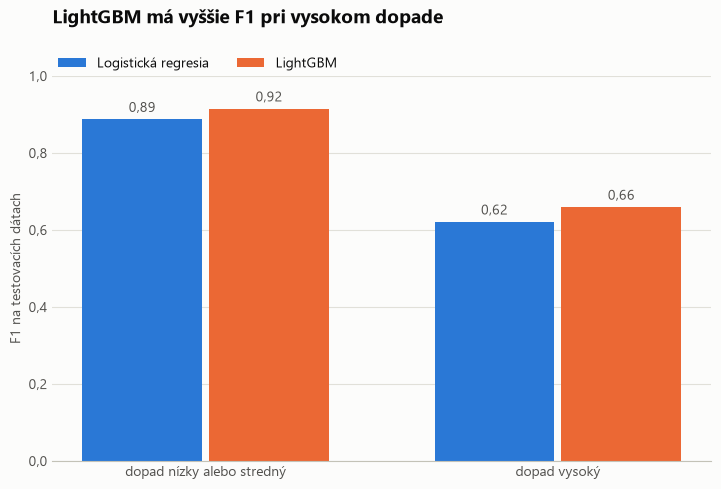

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5))
positions = np.arange(len(LABELS))
width = 0.36
for offset, name in zip((-width / 2, width / 2), MODEL_COLORS):
    values = per_class.loc[name, "F1"].reindex(LABELS).to_numpy()
    bars = ax.bar(positions + offset, values, width - 0.02, color=MODEL_COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{value:.2f}".replace(".", ",") for value in values], padding=3, color=INK_SECONDARY)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_xticks(positions, [f"dopad {label}" for label in LABELS])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.1f}".replace(".", ","))
ax.set_ylabel("F1 na testovacích dátach")
ax.set_title("LightGBM má vyššie F1 pri vysokom dopade", loc="left", fontsize=14, fontweight="bold", pad=38)
ax.legend(ncols=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0)
fig.savefig(FIGURES_DIR / "5_f1_2_triedy.png")
plt.show()

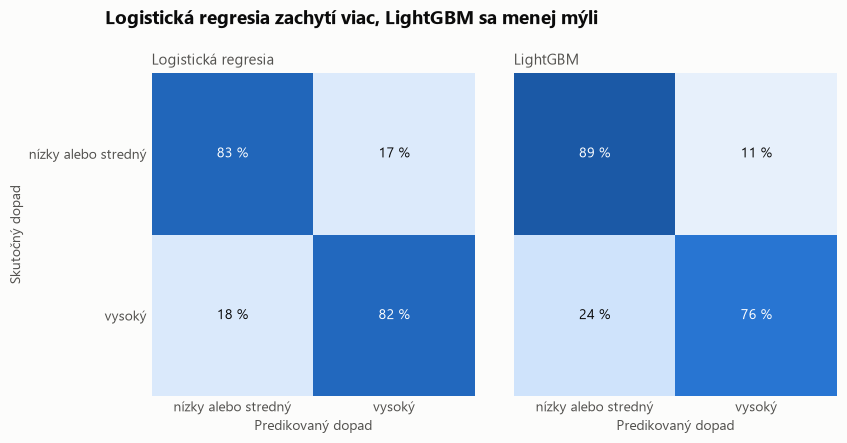

In [9]:
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, name in zip(axes, MODEL_COLORS):
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1], normalize="true")
    ax.imshow(matrix, cmap=blues, vmin=0, vmax=1)
    for row in range(2):
        for column in range(2):
            value = matrix[row, column]
            ax.text(column, row, f"{value * 100:.0f} %", ha="center", va="center", color="#ffffff" if value >= 0.6 else INK)
    ax.set_title(name, loc="left", fontsize=11, color=INK_SECONDARY)
    ax.set_xticks(range(2), LABELS)
    ax.set_yticks(range(2), LABELS)
    ax.set_xlabel("Predikovaný dopad")
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
axes[0].set_ylabel("Skutočný dopad")
fig.suptitle("Logistická regresia zachytí viac, LightGBM sa menej mýli", x=0.08, y=1.03, ha="left", fontsize=14, fontweight="bold")
fig.savefig(FIGURES_DIR / "6_matice_zamen_2_triedy.png")
plt.show()

## 7. Zhrnutie

Výsledky platia pre testovaciu množinu 1 530 incidentov, teda 30 % z 5 097 incidentov so známym dopadom. Tréningová množina má 3 567 incidentov. Vysoký dopad má 17,3 % incidentov v oboch častiach.

| Metrika | Triviálny model | Logistická regresia | LightGBM |
| --- | ---: | ---: | ---: |
| Macro F1 | 0,453 | 0,755 | 0,788 |
| Accuracy | 0,827 | 0,827 | 0,865 |
| Recall `vysoký` | 0,000 | 0,819 | 0,758 |
| Precision `vysoký` | 0,000 | 0,501 | 0,584 |
| ROC AUC | 0,500 | 0,905 | 0,912 |

**Vyhodnotenie:**

- Oba modely jasne prekonali triviálny model. Ten má síce accuracy 0,827, no iba preto, že vysoký dopad nepredikuje nikdy.
- LightGBM má spoľahlivo vyššie macro F1. Rozdiel je 0,033 s 95 % intervalom [0,011; 0,053].
- Logistická regresia zachytí viac incidentov s vysokým dopadom. Jej recall je o 0,061 vyšší s intervalom [0,018; 0,104], za cenu viacerých falošných poplachov.
- V zoradení incidentov podľa rizika sa modely nelíšia. Rozdiel ROC AUC je 0,007 s intervalom [-0,004; 0,018]. Rozdiel v ostatných metrikách teda vychádza najmä z toho, kde má model prah, a ten sa dá posunúť.
- Náhodné rozdelenie je len mierne optimistické. Na 1 179 testovacích incidentoch, ktorých zdroj model nevidel, je macro F1 0,745 a 0,778 a ROC AUC 0,887 a 0,895.

**Odporúčanie.** Ak je dôležitejšie nezmeškať incident s vysokým dopadom, vhodnejšia je logistická regresia. Ak sú drahé falošné poplachy, vhodnejší je LightGBM. Keďže zoraďujú incidenty rovnako dobre, dá sa prah ktoréhokoľvek modelu nastaviť podľa toho, koľko poplachov tím zvládne.

**Porovnanie s `predikcia.ipynb`.** Výsledky nie sú priamo porovnateľné. Úloha s dvoma triedami je ľahšia a náhodné rozdelenie nechá podobné incidenty z jedného zdroja v tréningu aj v teste.